# ASTR 596 Computer lab - Characterizing CCDs (50 points)

In this lab you will learn how to:
* read in a CCD image into python
* learn how to display a CCD image
* measure properties of that CCD image
* from a set of CCD Bias frames and Flat field frames, determine the readnoise and gain of the CCD

<i>Note: Enter in all code to the problems in the provided notebook cells. Questions to answer will be <b>bolded</b>.</i>  

<b>You need to execute all code cells regardless of whether they are part of a problem.</b>

All your answers should be entered in this notebook. Each student will need to hand in their own notebook by uploading it to GitHub following the instructions.

In the code places where you will need to put something or write your own code are specified by `#***************`  You will not get points for doing this unless explicitly noted.  Some of these things are just to make sure you are setting up your paths correctly.

**Due on Oct. 21st at Noon** to be handed into the "Characterizing CCDs" assignment in Module 7.

### Import modules

In [29]:
import os
from astropy.io import fits
from astropy.wcs import WCS
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import scoreatpercentile
import glob
%matplotlib inline
from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

### Define a function for displaying images

* We will want to look at images as we examine and analyze the data, so here will will define a function for displaying images. 
* This will handle getting the stretch of the image correct. 
* Feel free to play with the settings and colormap once you get the hang of the process.



In [30]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)

### Display raw science image

Text(0.5, 1.0, 'V-band Raw image')

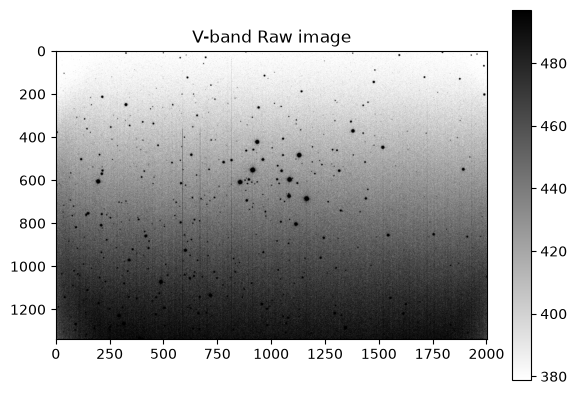

In [31]:
plt.figure()
data_vimraw, header_vimraw = fits.getdata('M29-0005g.fit',header=True)
imdisplay(data_vimraw)
plt.title("V-band Raw image")

### Display processed science image

Text(0.5, 1.0, 'V-band Processed image')

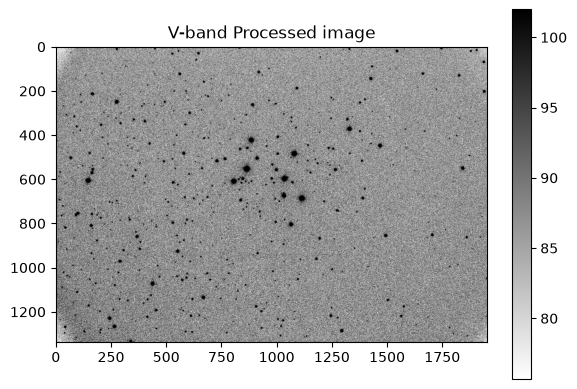

In [32]:
plt.figure()
data_vimproc, header_vimproc = fits.getdata('cazfdp-M29-0005g.fits',header=True)
imdisplay(data_vimproc)
plt.title("V-band Processed image")

## Problem 1 (5 points)

The two images above are the same exact image except that one is raw and one has been fully processed.  In the cell below, describe the origin of the differences between the two images.  I want you to be precise.  NOTE: This CCD has no overscan region so we only have the combined bias frames.  Also pay attention to the values in the colorbar.

answer goes here
1. **Colorbar / Count Offset (Bias & Dark Subtraction):** The raw image colorbar ranges from ~1050 to 1250 ADU, whereas the processed image ranges from ~20 to 120 ADU. This ~1000 ADU drop occurs because the combined **bias frame** (the intentional electronic zero-point offset) and **dark frame** (thermal electrons accumulated during the exposure, including hot pixels) have been subtracted.
2. **Spatial Uniformity (Flat-Field Division):** The raw image shows a strong top-to-bottom illumination gradient, edge darkening (vignetting), and circular shadows ("dust donuts"). Dividing by the normalized **flat-field frame** removes these large-scale optical gradients and small-scale pixel-to-pixel quantum efficiency variations, resulting in a flat, uniform sky background in the processed image.

### Display two flat field images

Text(0.5, 1.0, 'B-band Sky Flat')

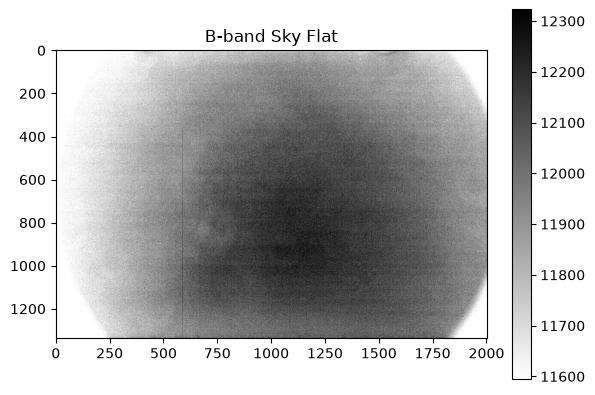

In [33]:
plt.figure()
data_flatb, header_flatb = fits.getdata('skyflat-0001b.fit',header=True)
imdisplay(data_flatb,v2perc=99)
plt.title("B-band Sky Flat")

Text(0.5, 1.0, 'V-band Sky Flat')

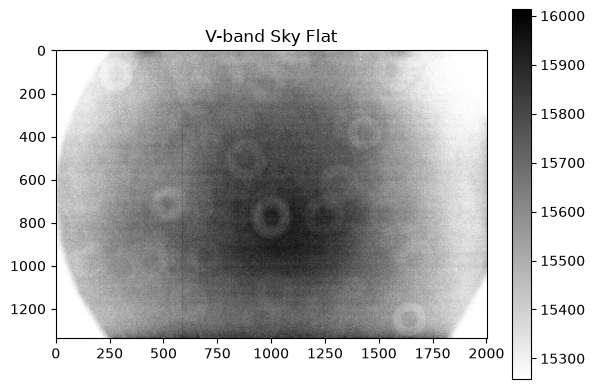

In [34]:
plt.figure()
data_flatv, header_flatv = fits.getdata('skyflat-0001v.fit',header=True)
imdisplay(data_flatv,v2perc=99)
plt.title("V-band Sky Flat")

## Problem 2 (5 points)
The two images above are two different flat field images.  The total number of counts depends on the brightness of the sky in the filter you are using at the time of observation.  Aside from a difference in the total counts, describe what the origins could be of the differences in the flatfields.  Pay attention to differences both at the large scale and the short scale.  

It is not required for the problem, but if you would like to better understand the differences between the two images, you can write a short bit of code that divides the two data arrays and then displays them.

answer goes here:

* **Small/Short Scale (Dust Donuts & Pixel QE):** The most notable difference is the location of the "dust donuts": out-of-focus shadows from dust grains sitting on the filters themselves. Because the B and V filters are separate pieces of glass, each has a different dust pattern (while dust on the common CCD window appears in the same place). Additionally, pixel-to-pixel quantum efficiency (sensitivity) varies with photon wavelength between the B and V bands.
* **Large Scale (Illumination Gradients & Vignetting):** At the large scale, the twilight sky has a wavelength-dependent spatial brightness gradient, and optical vignetting/scattered light across the telescope's focal plane behaves slightly differently between the B and V filters.

Text(0.5, 1.0, 'Ratio of B-band to V-band Sky Flat')

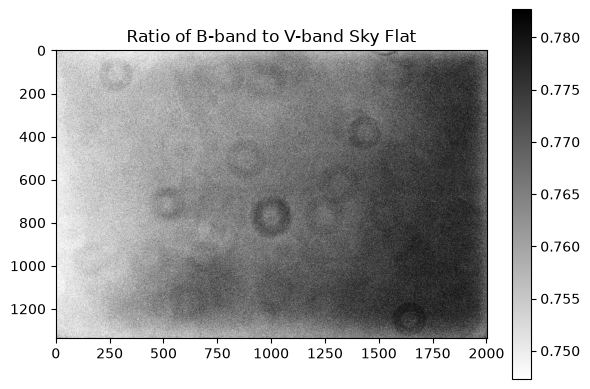

In [35]:
plt.figure()
imdisplay(
    np.array(data_flatb, dtype=float) / np.array(data_flatv, dtype=float),
    v1perc=5,
    v2perc=95,
)
plt.title("Ratio of B-band to V-band Sky Flat")

### Display or manipiulate a section of an image

You can feed sections of images to functions and they will either perform the necessary operations, or in the following case, display only those sections.  You may find it useful to consult the first python notebook we did, which had instructions on how to slice arrays.

## Problem 3 (5 points) - properly display a region of the image

You will need to complete the section of code below to display rows 400-900 and columns 750-1250.  You must compare the cutout to the full image above to make sure you are properly addressing rows and columns.

Text(0.5, 1.0, 'cutout of V-band image')

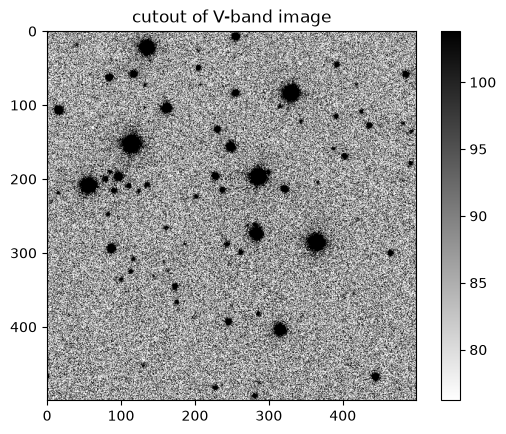

In [36]:
#to display only a section of an image you can perform the following operation
#this displays the section of the image
#***************** fill in the missing array range.
imdisplay(data_vimproc[400:900, 750:1250])
plt.title("cutout of V-band image")
#NOTE: that it renumbers the pixels and does *not* refer back to the original image.  
#It also bases the colorbar stretch on the pixels in the subsection that you are displaying

#### Compute statistics on an image
You can pass an image to numpy and compute statistics on it.  In the example below, I show how to compute the standard deviation of all pixel values of a bias image.

I have included two bias images in this directory, numbers 20 and 21


the standard deviation of the Bias frame is 42.08174498305511


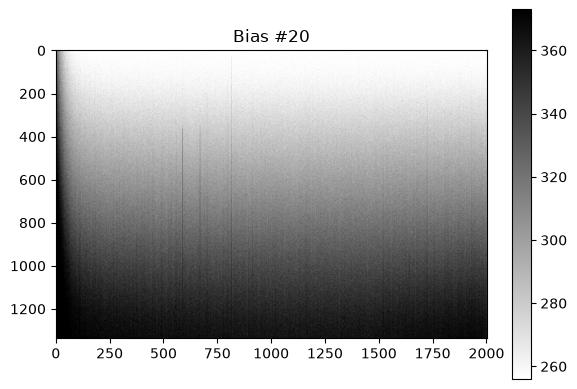

In [37]:
#first read in a bias image
plt.figure()
data_bias1, header_bias1 = fits.getdata('bias-0020.fit',header=True)
imdisplay(data_bias1)
plt.title("Bias #20")

print("the standard deviation of the Bias frame is", np.std(data_bias1))

## Problem 4 (5 points) - Compute the standard deviation of a subsection of the bias image
I would like you to write a peice of well-commented code that
1. displays the bias image extending over rows 600-800 and columns 1000-1200.
2. Measure the standard deviation of the pixels in this section of the bias and print it out.

Then I would like you to explain any differences in the stanard deviation between this subsection and that of the full image.


The standard deviation of the Bias frame subsection is 12.986602696986422


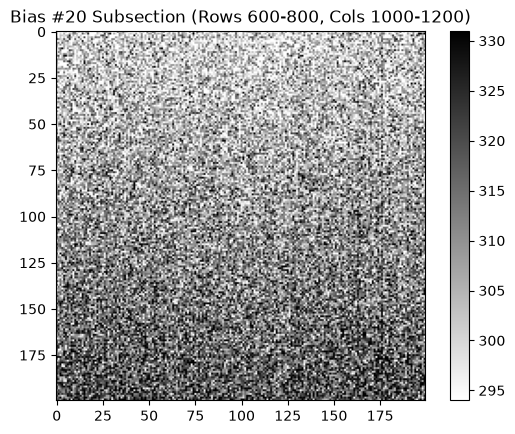

In [38]:
# Put your code here
# ***********************
plt.figure()

# Slice the bias array over rows 600-800 (y-axis) and columns 1000-1200 (x-axis)
bias1_sub = data_bias1[600:800, 1000:1200]

# Display the subsection of the bias frame
imdisplay(bias1_sub)
plt.title("Bias #20 Subsection (Rows 600-800, Cols 1000-1200)")

# Compute and print the standard deviation of the pixels in this subsection
std_bias1_sub = np.std(bias1_sub)
print("The standard deviation of the Bias frame subsection is", std_bias1_sub)

put your answer here

The standard deviation of the $200 \times 200$ central subsection is smaller than that of the full bias frame because the full image includes large-scale 2D spatial variations (electronic gradients across the chip, edge effects, or defective edge pixels) that artificially inflate the global standard deviation. Focusing on a small, roughly-uniform central region excludes these large-scale systematic structures, giving a cleaner measure of local pixel-to-pixel variation.

## Problem 5 (15 points) - compute the readnoise from two bias frames
Using the coding tools we described above and have used in the class, I would like you to 
1. write a well-commented program that measures the READNOISE using two bias frames and prints it out.  The name of the second bias frame is `bias-0021.fit`, which I have written code to read in. You cannot just use the answer from the question above, which was derived from one bias frame.
2. Describe why you can't jsut use one bias frame.
3. Comment on whether the number you derived is in electrons or ADU and justify your answer.

In [39]:
# read in the other bias image
data_bias2, header_bias2 = fits.getdata("bias-0021.fit", header=True)

# convert both arrays to floating point arrays. This is needed to make sure that
# arithmetic operations will work as the images are otherwise positive definite (UNSIGNED) integers.
data_bias1 = np.array(data_bias1, "f")
data_bias2 = np.array(data_bias2, "f")

# *******************
# Your code here

# Subtract the two bias frames to remove the fixed 2D spatial bias structure
bias_diff = data_bias1 - data_bias2

# Use the clean central subsection (rows 600-800, cols 1000-1200) to avoid bad edge pixels/artifacts
bias_diff_sub = bias_diff[600:800, 1000:1200]

# Because the variance of the difference of two independent frames with equal readnoise
# is the sum of their individual variances (sigma_diff^2 = 2 * sigma_RN^2),
# we divide the standard deviation of the difference image by sqrt(2).
readnoise_adu = np.std(bias_diff_sub) / np.sqrt(2.0)

print("Readnoise of Bias Frame in ADU is = ", readnoise_adu)

Readnoise of Bias Frame in ADU is =  10.202482898585084


put answer to part 2 and 3 here:

**Part 2**
A single bias frame consists of two components: (1) a deterministic, fixed 2D electronic offset pattern (spatial variations, row/column gradients, and pixel-to-pixel zero-point offsets) and (2) random Gaussian electronic read noise introduced during readout. Subtracting the two removes the identical, fixed 2D patterns, but does not remove the random noise

**Part 3**
Our number is in **ADU** because that is the value the CCD records and saves output in. 

## Problem 6 (15 points) - Compute gain of detector using flat field
1. Using your answer to Problem 5 and statistics of the B-band flat field image above, you will need to write a program that computes the gain of the CCD and prints it out.  Specify the units of the gain.  This will work for any flat-field image, but I just used the B-band (`data_flatb`) so that everyone is on the same page.

2. Include a text field with your mathematical derivation in LaTeX, which you can included in the text field.

3. Check your answer against the value in the header.  You can bring this value using `print(header_flatb['EGAIN'])`, where EGAIN is the header keyword for the gain.  Compute how accurate your estimate is.

**HINT:** You will need to think about the measured standard deviation of the pixel values in a section of the flatfield that is relatively uniform.  You can use that, and your knowledge of Poisson statistics and the way the gain affects the counts, to compute the gain.

### Mathematical Derivation of CCD Gain

Let $g$ be the CCD gain in units of $e^-/\text{ADU}$. 

First, the true flat-field signal in ADU ($\bar{F}_{\text{ADU}}$) in a uniform subsection of the detector is obtained by subtracting the mean bias level ($\bar{B}_{\text{ADU}}$) from the measured raw flat-field mean ($\bar{F}_{\text{raw, ADU}}$):
$$\bar{F}_{\text{ADU}} = \bar{F}_{\text{raw, ADU}} - \bar{B}_{\text{ADU}}$$

Converting this mean signal into physical photoelectrons ($N_e$) via the gain $g$:
$$N_e = g \cdot \bar{F}_{\text{ADU}}$$

Photon arrival and photoelectron generation follow **Poisson statistics**, meaning the intrinsic photon shot noise in electrons is:
$$\sigma_{\text{shot}, e^-} = \sqrt{N_e} = \sqrt{g \cdot \bar{F}_{\text{ADU}}}$$

Converting this shot noise back into units of ADU by dividing by the gain $g$:
$$\sigma_{\text{shot, ADU}} = \frac{\sigma_{\text{shot}, e^-}}{g} = \frac{\sqrt{g \cdot \bar{F}_{\text{ADU}}}}{g} = \sqrt{\frac{\bar{F}_{\text{ADU}}}{g}}$$

The total measured variance ($\sigma_{\text{flat, ADU}}^2$) in a uniform region of the flat-field frame is the quadrature sum of the Poisson photon shot noise and the detector read noise ($\sigma_{\text{RN, ADU}}$):
$$\sigma_{\text{flat, ADU}}^2 = \sigma_{\text{shot, ADU}}^2 + \sigma_{\text{RN, ADU}}^2 = \frac{\bar{F}_{\text{ADU}}}{g} + \sigma_{\text{RN, ADU}}^2$$

Solving this equation for the gain $g$:
$$\frac{\bar{F}_{\text{ADU}}}{g} = \sigma_{\text{flat, ADU}}^2 - \sigma_{\text{RN, ADU}}^2$$

$$g = \frac{\bar{F}_{\text{ADU}}}{\sigma_{\text{flat, ADU}}^2 - \sigma_{\text{RN, ADU}}^2} = \frac{\bar{F}_{\text{raw, ADU}} - \bar{B}_{\text{ADU}}}{\sigma_{\text{flat, ADU}}^2 - \sigma_{\text{RN, ADU}}^2} \quad \left[\frac{e^-}{\text{ADU}}\right]$$

In [40]:
# ***********
# your code goes here

# Convert the B-band flat field to a float array for accurate arithmetic
flatb_float = np.array(data_flatb, "f")

# Select a uniform, defect-free subsection of the B-band flat and bias frame
# (using the same clean central region: rows 600-800, columns 1000-1200)
flatb_sub = flatb_float[600:800, 1000:1200]
bias1_sub = data_bias1[600:800, 1000:1200]

# Compute the mean bias-subtracted flat-field signal in ADU
mean_flat_adu = np.mean(flatb_sub) - np.mean(bias1_sub)

# Measure the standard deviation (and variance) of the pixel values in the uniform flat subsection
std_flat_adu = np.std(flatb_sub)

# Compute the gain in e-/ADU: g = mean_signal / (sigma_flat^2 - sigma_RN^2)
gain_calc = mean_flat_adu / (std_flat_adu**2 - readnoise_adu**2)

# Retrieve the factory/header gain value (in e-/ADU)
gain_header = header_flatb["EGAIN"]

# Compute the percentage difference between our estimate and the header value
perc_diff = np.abs(gain_calc - gain_header) / gain_header * 100.0

print("gain = ", gain_calc, "e-/ADU")
print("gain from header keyword = ", gain_header, "e-/ADU")
print("percentage difference = ", perc_diff, "%")

gain =  1.1867548658992149 e-/ADU
gain from header keyword =  1.6200000047683716 e-/ADU
percentage difference =  26.74352701197074 %
